<a href="https://colab.research.google.com/github/HalfNHalf3/Final-Project-volleyball-overlay/blob/main/Volleyball_AI_Development.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
import shutil
from pathlib import Path
from google.colab import drive

# Clean up any local dummy folder that is blocking the mount
drive_path = Path("/content/drive")
if drive_path.exists() and not drive_path.is_mount():
    print("Cleaning up existing unmounted directory to prepare for mounting...")
    shutil.rmtree(drive_path, ignore_errors=True)

print("Mounting Google Drive...")
drive.mount("/content/drive", force_remount=True)

Cleaning up existing unmounted directory to prepare for mounting...
Mounting Google Drive...
Mounted at /content/drive


In [12]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/VolleyballAI"
)

VIDEO_DIR = PROJECT_DIR / "videos" / "raw"
DATASET_DIR = PROJECT_DIR / "datasets"
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"
EXPORT_DIR = PROJECT_DIR / "exports"

for folder in [
    VIDEO_DIR,
    DATASET_DIR,
    MODEL_DIR,
    RESULTS_DIR,
    EXPORT_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folders are ready.")

Project folders are ready.


In [ ]:
%pip install -q ultralytics opencv-python-headless fastapi uvicorn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 8.1 MB/s eta 0:00:00


In [ ]:
import cv2
import numpy as np
import torch
import ultralytics

print("OpenCV:", cv2.__version__)
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
OpenCV: 4.14.0
PyTorch: 2.11.0+cpu
Ultralytics: 8.4.183
CUDA available: False


In [16]:
from pathlib import Path
import cv2

# Let's search your Google Drive to find exactly where the video file is stored
drive_root = Path("/content/drive/MyDrive")
found_paths = list(drive_root.rglob("*volleyball vid 1min15*"))

if not found_paths:
    print("Could not find any file matching 'volleyball vid 1min15' in your Google Drive.")
    print("Please check if the video has finished uploading to Drive, or check its spelling.")
else:
    print(f"Found {len(found_paths)} matching file(s):")
    for path in found_paths:
        print(f"- {path}")

    # Use the first match found
    video_path = found_paths[0]
    print(f"\nUsing found video path: {video_path}")

    cap = cv2.VideoCapture(str(video_path))
    if cap.isOpened():
        fps = cap.get(cv2.CAP_PROP_FPS)
        frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        duration = frame_count / fps if fps > 0 else 0

        print(f"\nResolution: {width} x {height}")
        print(f"FPS: {fps:.2f}")
        print(f"Frames: {frame_count}")
        print(f"Duration: {duration:.2f} seconds")
        cap.release()
    else:
        print("Could not open the found video file.")

Found 1 matching file(s):
- /content/drive/MyDrive/VolleyballAI/videos/raw/volleyball vid 1min15.mp4

Using found video path: /content/drive/MyDrive/VolleyballAI/videos/raw/volleyball vid 1min15.mp4

Resolution: 1920 x 1080
FPS: 30.00
Frames: 2257
Duration: 75.23 seconds


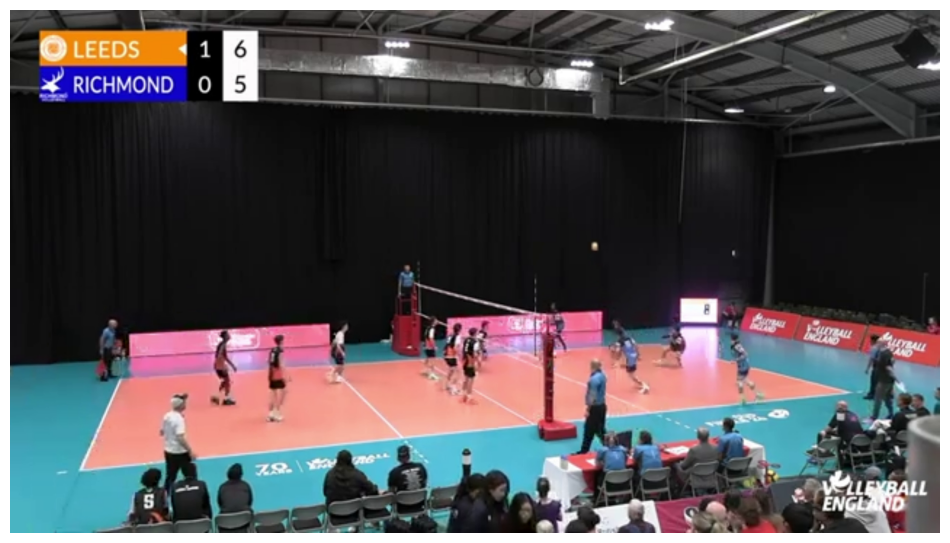

In [30]:
import matplotlib.pyplot as plt

cap = cv2.VideoCapture(str(video_path))

cap.set(cv2.CAP_PROP_POS_MSEC, 43000)
success, frame = cap.read()
cap.release()

if success:
    frame_rgb = cv2.cvtColor(
        frame, cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(12, 7))
    plt.imshow(frame_rgb)
    plt.axis("off")
    plt.show()
else:
    print("Could not read the selected frame.")

PyTorch: 2.11.0+cu130
CUDA available: True
Model classes: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 6

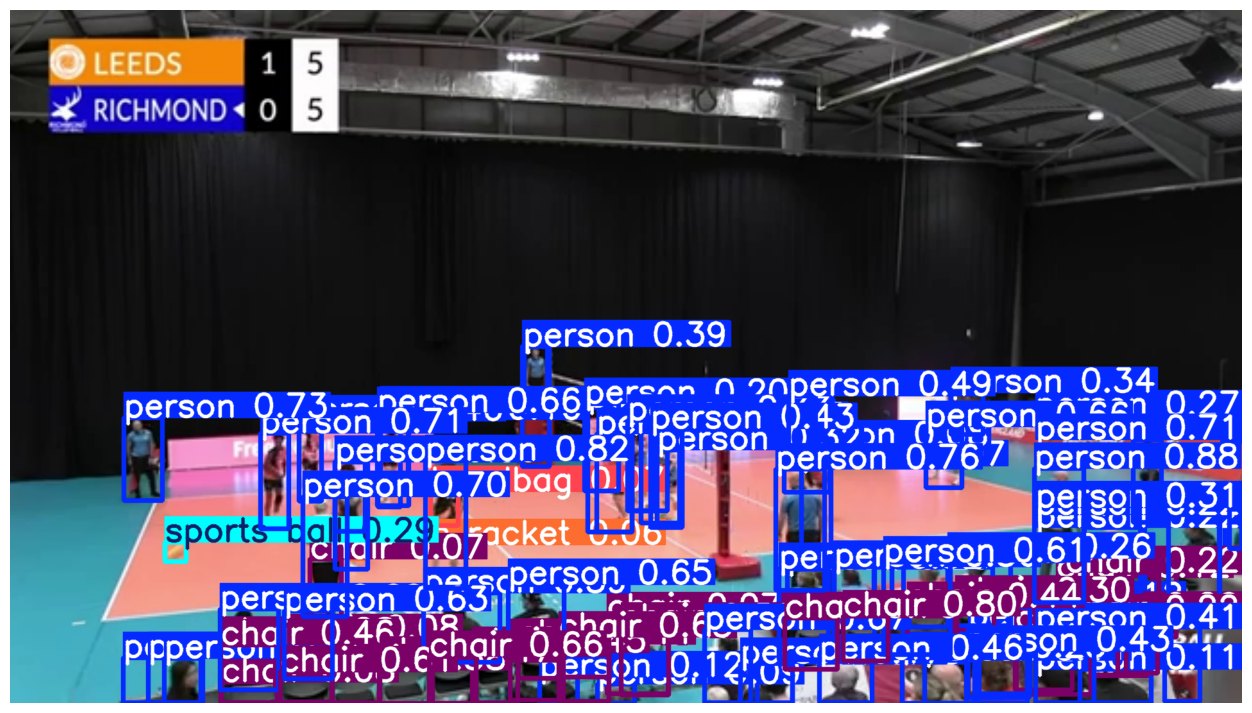

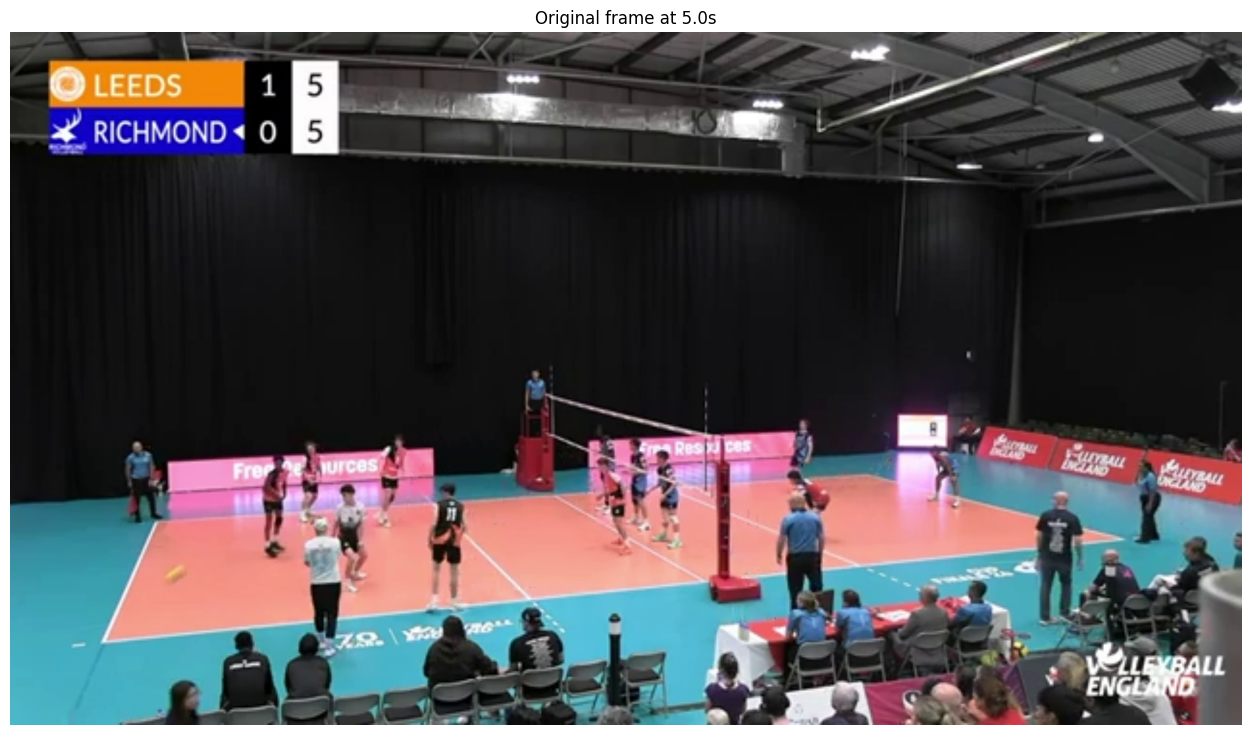

In [36]:

from ultralytics import YOLO
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import torch

# Use the same model as your previous experiment
model = YOLO("yolo11n.pt")

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Model classes:", model.names)

# Use your existing video_path variable
cap = cv2.VideoCapture(str(video_path))

if not cap.isOpened():
    raise RuntimeError(f"Cannot open video: {video_path}")

# Change this to a timestamp where the ball is clearly visible
timestamp_seconds = 5.0

cap.set(cv2.CAP_PROP_POS_MSEC, timestamp_seconds * 5000)
success, frame = cap.read()
cap.release()

if not success:
    raise RuntimeError("Could not read the selected frame.")

print("Frame shape:", frame.shape)

# First, inspect predictions at the original image resolution
result = model.predict(
    source=frame,
    imgsz=1280,
    conf=0.01,
    iou=0.7,
    max_det=100,
    verbose=False
)[0]

print("\nNumber of detections:", len(result.boxes))

for box in result.boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])
    coordinates = box.xyxy[0].tolist()

    print(
        f"Class={class_id} "
        f"Name={model.names[class_id]} "
        f"Confidence={confidence:.4f} "
        f"Box={[round(v, 1) for v in coordinates]}"
    )

# Draw ALL detections
annotated = result.plot()

plt.figure(figsize=(16, 9))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

# Also show the original frame for comparison
plt.figure(figsize=(16, 9))
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.title(f"Original frame at {timestamp_seconds}s")
plt.axis("off")
plt.show()


Balls detected: 0


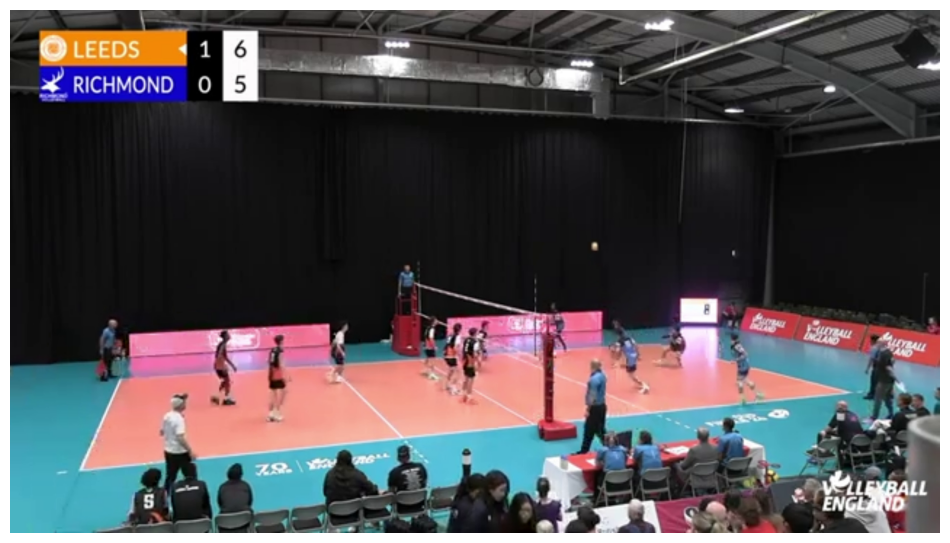

In [31]:
try:
    from ultralytics import YOLO
except ImportError:
    print("Ultralytics library not found. Installing now...")
    !pip install -q ultralytics
    from ultralytics import YOLO

import cv2
import matplotlib.pyplot as plt

# Load a general-purpose pretrained detector.
model = YOLO("yolo11n.pt")

cap = cv2.VideoCapture(str(video_path))

# Inspect a frame approximately 5 seconds into the video.
cap.set(cv2.CAP_PROP_POS_MSEC, 43000)
success, frame = cap.read()
cap.release()

if not success:
    raise RuntimeError("Could not read video frame.")

results = model.predict(
    source=frame,
    imgsz=640,
    conf=0.15,
    verbose=False
)

annotated = frame.copy()
ball_count = 0

for result in results:
    if result.boxes is None:
        continue

    for box in result.boxes:
        class_id = int(box.cls[0])

        # COCO class 32 is "sports ball".
        if class_id != 32:
            continue

        x1, y1, x2, y2 = map(
            int, box.xyxy[0].tolist()
        )

        confidence = float(box.conf[0])
        ball_count += 1

        cv2.rectangle(
            annotated,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        cv2.putText(
            annotated,
            f"Ball {confidence:.2f}",
            (x1, max(20, y1 - 8)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )

print("Balls detected:", ball_count)

plt.figure(figsize=(12, 7))
plt.imshow(
    cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
)
plt.axis("off")
plt.show()